# DFND on the exact shell-opening subset

Does atom deletion change native exterior connectivity in the direction
established independently by [system.ipynb](system.ipynb)? Compare the parent
and child at the same **1.4 Å** probe, then test the child's **3 Å** enclosed
origin and **5 Å** finite-hull exclusion controls.

This notebook reads the committed input, protocol and independent reference
in its own fresh kernel. It runs no original provider, makes no server
requests and overwrites no artifacts. Family names and exterior-link
clusters are observations; the reference does not prescribe an exact
physical mouth count or a global number of cavities.

In [1]:
import hashlib
import html
import json
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from pyunitwizard import QuantityRecord
from scipy.spatial import ConvexHull

import topomt as tmt
from topomt import pyunitwizard as puw
from topomt.dfnd import DelaunayFlowNetwork

DATA = Path('artifacts/shell_with_opening_v1')
protocol_bytes = (DATA/'protocol.json').read_bytes()
reference_bytes = (DATA/'system_reference.json').read_bytes()
protocol = json.loads(protocol_bytes); reference = json.loads(reference_bytes)
input_bytes = Path(protocol['source_file']).read_bytes(); fixture = json.loads(input_bytes)
parent_dir = Path(protocol['parent_directory'])
parent = json.loads((parent_dir/protocol['parent_input_file']).read_bytes())
assert hashlib.sha256(input_bytes).hexdigest() == protocol['input_sha256'] == reference['input_sha256']
assert reference['protocol_sha256'] == hashlib.sha256(protocol_bytes).hexdigest()
assert reference['reference_checks'] == 'passed'
for relative, digest in protocol['parent_preserved_files'].items():
    assert hashlib.sha256((parent_dir/relative).read_bytes()).hexdigest() == digest

def quantity(record, field, unit):
    return QuantityRecord.from_dict(record).to_quantity(field=field, unit=unit)

def values(record, field, unit):
    return np.asarray(puw.get_value(quantity(record, field, unit), to_unit=unit))

def qrecord(data, unit, field):
    return QuantityRecord.from_quantity(puw.quantity(data, unit), field=field).to_dict()

def native_quantity(data, native_unit, target_unit, field):
    converted = puw.get_value(puw.quantity(data, native_unit), to_unit=target_unit)
    return qrecord(float(converted), target_unit, field)

def table(headers, rows):
    lines = ['| '+' | '.join(headers)+' |', '| '+' | '.join(['---']*len(headers))+' |']
    lines += ['| '+' | '.join(str(value) for value in row)+' |' for row in rows]
    display(Markdown(chr(10).join(lines)))

query = {key:(quantity(value,key,'angstroms') if isinstance(value,dict) else value)
         for key,value in protocol['query'].items()}
parent_ids = np.asarray(fixture['derivation']['parent_atom_indices'], dtype=int)
coords = values(fixture['coordinates'],'coordinates','angstroms')
radii = values(fixture['atom_radii'],'atom_radii','angstroms')
parent_coords = values(parent['coordinates'],'coordinates','angstroms')
origin = values(protocol['origin'],'origin','angstroms')
origin_nm = values(protocol['origin'],'origin','nm')
atol = float(values(protocol['tolerances']['length_absolute'],'length_absolute','angstroms'))

def prepare(source, mapping):
    network = DelaunayFlowNetwork.from_coordinates_and_radii(
        quantity(source['coordinates'],'coordinates','angstroms'),
        quantity(source['atom_radii'],'atom_radii','angstroms'), atom_indices=mapping,
        epsilon=quantity(source['epsilon'],'epsilon','angstroms'))
    vertices = network.atom_coords[network.tetra_atoms]  # Explicit native nm storage.
    matrices = np.swapaxes(vertices[:,1:]-vertices[:,:1],1,2)
    bary = np.linalg.solve(matrices,(origin_nm-vertices[:,0])[:,:,None])[:,:,0]
    tol = protocol['tolerances']['barycentric_absolute']
    containing = set(map(int,np.flatnonzero(np.all(bary>=-tol,axis=1)&(bary.sum(axis=1)<=1+tol))))
    assert containing
    return network, containing

network, containing = prepare(fixture, parent_ids)
parent_network, parent_containing = prepare(parent, np.arange(len(parent_coords)))
table(['Input', 'Balls', 'Carrier cells', 'Origin-containing cell IDs (local to each mesh)'], [
    ['Closed parent',len(parent_coords),parent_network.n_tetrahedra,sorted(parent_containing)],
    ['Opened child',len(coords),network.n_tetrahedra,sorted(containing)]])

| Input | Balls | Carrier cells | Origin-containing cell IDs (local to each mesh) |
| --- | --- | --- | --- |
| Closed parent | 72 | 191 | [40] |
| Opened child | 66 | 173 | [152] |

## Match a spatial question, preserve atom identity

Barycentric containment selects the declared origin before ranking outputs.
Parent and child cell IDs have separate namespaces because deletion changes
the triangulation. The advanced public constructor's `atom_indices` mapping
keeps **parent atom IDs** in child raw supports. Local array offsets remain
available separately. Neither a largest-component heuristic nor a family
label selects the region.

Both networks use the frozen query, `min_size=0`, zero physical tolerances
and the same explicit epsilon. No parameter is adjusted to obtain agreement.

In [2]:
def observe(active_network, selected_cells, probe, min_size=0):
    result = active_network.get_topography(probe_radius=puw.quantity(float(probe),'angstroms'),
        **{**query,'min_size':min_size})
    raw = result['raw']
    candidates = [component for component in raw['wet_components']
                  if selected_cells & set(component['tetrahedron_ids'])]
    assert len(candidates)<=1
    central = candidates[0] if candidates else None
    resident_ids = [int(cell['tetrahedron_id']) for cell in raw['tetrahedra'] if cell['residence_state']=='resident']
    for cell in raw['tetrahedra']:
        assert cell['atom_indices'] == active_network.atom_indices_map[cell['local_atom_indices']].tolist()
    record = {'probe_radius':qrecord(float(probe),'angstroms','probe_radius'),
        'raw_component_count':len(raw['wet_components']), 'resident_node_count':len(resident_ids),
        'resident_tetrahedron_ids':resident_ids,
        'central_family':central['family'] if central else 'no_wet_component',
        'central_nodes':int(central['n_nodes']) if central else 0,
        'central_resident_nodes':int(central['n_resident_nodes']) if central else 0,
        'central_tetrahedron_ids':list(map(int,central['tetrahedron_ids'])) if central else [],
        'central_resident_tetrahedron_ids':list(map(int,central['resident_tetrahedron_ids'])) if central else [],
        'central_atom_indices':list(map(int,central['atom_indices'])) if central else [],
        'central_support_key':central['support_key'] if central else None,
        'central_component_key':central['component_key'] if central else None,
        'central_external_links':int(central['n_external_links']) if central else None,
        'central_in_compatibility_view':bool(central['include_in_compatibility_view']) if central else False,
        'central_solvent_volume_estimate':native_quantity(central['volume_solvent_estimate'],'nm**3','angstroms**3',
            'central_solvent_volume_estimate') if central else None,
        'reported_counts':{key:len(bucket) for key,bucket in result['wet'].items()}}
    return record,result,central

parent_control, parent_result, _ = observe(parent_network,parent_containing,1.4)
assert parent_control['central_family']=='void' and parent_control['central_external_links']==0
assert parent_control['central_resident_nodes']>0
anchors=[]; results=[]; components=[]
for declared in reference['experiments']:
    probe = float(values(declared['probe_radius'],'probe_radius','angstroms'))
    observed,result,component = observe(network,containing,probe)
    observed.update(experiment_id=declared['id'],reference_expectation=declared['expectation'])
    anchors.append(observed); results.append(result); components.append(component)
assert anchors[0]['central_resident_nodes']>0 and anchors[0]['central_external_links']>0
assert anchors[1]['central_resident_nodes']>0 and anchors[1]['central_external_links']==0
assert anchors[1]['central_family']=='void'
assert anchors[2]['resident_node_count']==anchors[2]['raw_component_count']==0
table(['Input / probe (Å)','Central family','Central resident / total cells','Exterior-link clusters','Global raw wet regions'],
    [[name,row['central_family'],f"{row['central_resident_nodes']} / {row['central_nodes']}",
      row['central_external_links'],row['raw_component_count']]
     for name,row in [('Parent / 1.4',parent_control),*[(f'Child / {probe:g}',row)
                     for probe,row in zip((1.4,3.,5.),anchors)]]])

| Input / probe (Å) | Central family | Central resident / total cells | Exterior-link clusters | Global raw wet regions |
| --- | --- | --- | --- | --- |
| Parent / 1.4 | void | 33 / 33 | 0 | 1 |
| Child / 1.4 | pocket | 35 / 35 | 1 | 1 |
| Child / 3 | void | 9 / 9 | 0 | 1 |
| Child / 5 | no_wet_component | 0 / 0 | None | 0 |

The checks concern exterior connectivity of the origin-containing region
and finite-hull residence. They do not prescribe the child's open family
name or a global cavity count. At 5 Å, an absent component has no defined
exterior-link count; the report uses `null`, rather than inventing a zero
count for a nonexistent object.

## Where does DFND connect to the exterior?

Inspect every exterior link of the central child region at 1.4 Å. Map its
local triangular faces back to parent IDs and verify the reference's
unchanged-wall constraint. Gate radii and triangle areas are converted from
their explicit native nm/nm² storage to Å/Å². These geometric triangle areas
are not solvent-accessible aperture areas.

| Exterior-link ID | Contact faces (parent IDs) | Minimum gate radius (Å) | Triangle area sum (Å²) |
| --- | --- | --- | --- |
| 1 | [[6, 7, 8]] | 2.010131 | 16.148008 |

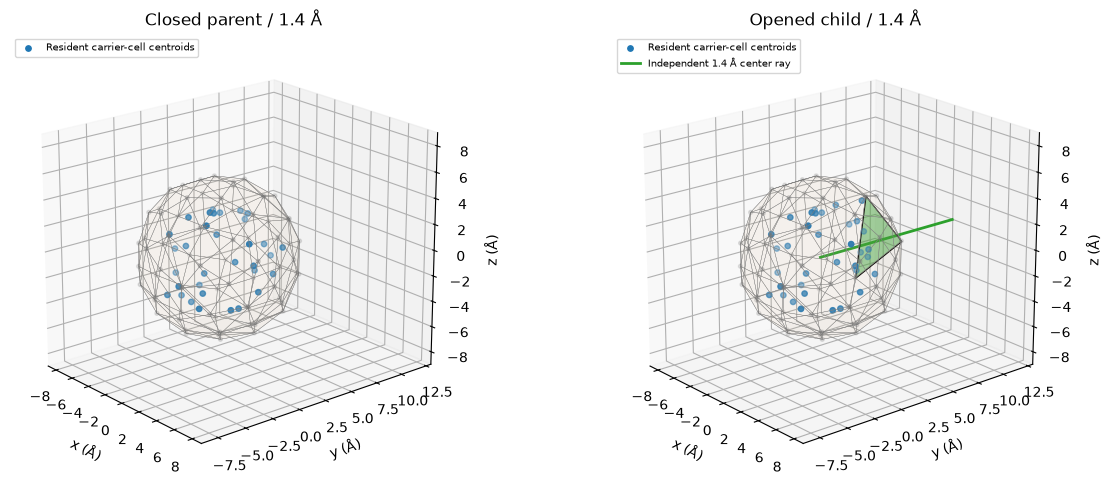

In [3]:
new_faces = set(map(tuple,reference['contact_reference']['new_child_hull_faces_parent_ids']))
unchanged_faces = set(map(tuple,reference['contact_reference']['unchanged_child_hull_faces_parent_ids']))
links=[]
central = components[0]
raw = results[0]['raw']
for link in raw['external_links']:
    if link['external_link_id'] not in central['external_link_ids']:
        continue
    faces = [tuple(sorted(map(int,parent_ids[face]))) for face in link['faces']]
    assert faces and set(faces)<=new_faces and set(faces).isdisjoint(unchanged_faces)
    assert set(link['atom_indices'])=={atom for face in faces for atom in face}
    for face_id in link['face_ids']:
        records = [face for face in raw['faces'] if face['face_id']==face_id]
        assert records and all(face['neighbor_tetrahedron_id']==-1 and face['permeability_state']=='permeable' for face in records)
    links.append({'external_link_id':int(link['external_link_id']), 'face_ids':list(map(int,link['face_ids'])),
        'faces_parent_ids':[list(face) for face in faces], 'atom_indices':list(map(int,link['atom_indices'])),
        'support_key':link['external_link_support_key'],
        **{key:native_quantity(link[key],'nm','angstroms',key) for key in ['R_gate_min','R_gate_mean','R_gate_max']},
        'area_geometric':native_quantity(link['area_geometric'],'nm**2','angstroms**2','area_geometric')})
assert len(links)==anchors[0]['central_external_links']
contact_analysis = {'probe_radius':anchors[0]['probe_radius'], 'all_contacts_on_new_child_hull_faces':True,
    'links':links, 'physical_mouth_count':'not_established_by_this_reference'}
table(['Exterior-link ID','Contact faces (parent IDs)','Minimum gate radius (Å)','Triangle area sum (Å²)'],
    [[link['external_link_id'],link['faces_parent_ids'],
      f"{float(values(link['R_gate_min'],'R_gate_min','angstroms')):.6f}",
      f"{float(values(link['area_geometric'],'area_geometric','angstroms**2')):.6f}"] for link in links])
fig = plt.figure(figsize=(12,4.8), constrained_layout=True)
for panel,(points,active_network,observation,title) in enumerate([
    (parent_coords,parent_network,parent_control,'Closed parent / 1.4 Å'),
    (coords,network,anchors[0],'Opened child / 1.4 Å')],start=1):
    ax = fig.add_subplot(1,2,panel,projection='3d')
    ax.add_collection3d(Poly3DCollection(points[ConvexHull(points).simplices],facecolor='tan',edgecolor='grey',alpha=.05,linewidth=.25))
    ax.scatter(*points.T,s=8,color='dimgray',alpha=.5)
    ids = observation['central_resident_tetrahedron_ids']
    centers = points[active_network.tetra_atoms[ids]].mean(axis=1)
    ax.scatter(*centers.T,s=15,color='tab:blue',label='Resident carrier-cell centroids')
    if panel==2:
        for index,link in enumerate(links):
            local_faces = [[int(np.flatnonzero(parent_ids==atom)[0]) for atom in face] for face in link['faces_parent_ids']]
            ax.add_collection3d(Poly3DCollection(points[local_faces],facecolor=f'C{index+2}',edgecolor='black',alpha=.45,linewidth=.8))
        terminal = values(reference['escape_witness']['terminal_point'],'terminal_point','angstroms')
        ax.plot(*np.stack([origin,terminal]).T,color='tab:green',lw=2,label='Independent 1.4 Å center ray')
    ax.set(xlim=(-9,9),ylim=(-9,13),zlim=(-9,9),xlabel='x (Å)',ylabel='y (Å)',zlabel='z (Å)',title=title)
    ax.set_box_aspect((18,22,18)); ax.view_init(elev=20,azim=-40); ax.legend(fontsize=7,loc='upper left')
plt.show()

Blue centroids show carrier support, rather than cavity boundaries. Colored
contact triangles are native clusters on newly exposed hull faces. Their
localization agrees with the independent unchanged-wall constraint. A single
cap and a single access witness do not establish exactly one physical mouth.

## Sweep, sufficient bounds and reporting

Reuse the parent's fixed 49 probes from 0.2 to 5 Å. Check access, enclosure
or exclusion only where the independent sufficient bounds apply; keep the
remaining intervals unresolved. Resident-cell availability must be nested
as the probe grows. Component counts and contact-cluster counts need not be
monotone. The observed native transitions are not physical thresholds.

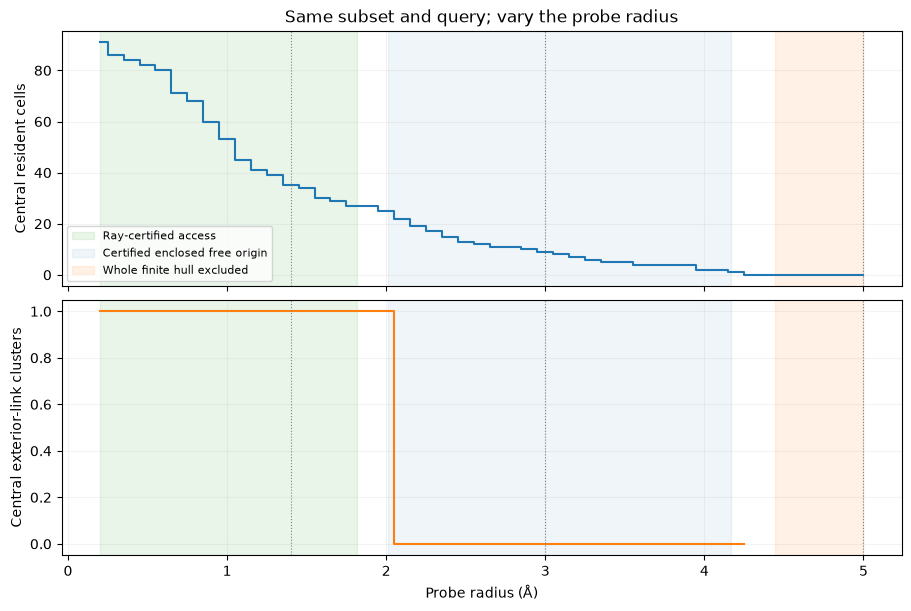

| min_size | Raw central resident / total cells | Central record reported |
| --- | --- | --- |
| 0 | 35 / 35 | True |
| 36 | 35 / 35 | False |

In [4]:
ray_bound = float(values(reference['escape_witness']['minimum_clearance'],'minimum_clearance','angstroms'))
wall_bound = float(values(reference['certificates']['maximum_face_cover_radius'],'maximum_face_cover_radius','angstroms'))-radii.min()
center_bound = float(values(reference['certificates']['center_clearance'],'center_clearance','angstroms'))
exclusion_bound = float(values(reference['certificates']['enclosing_radius'],'enclosing_radius','angstroms'))-radii.min()
probes = values(fixture['probe_sweep'],'probe_sweep','angstroms')
sweep=[]
for probe in probes:
    observed,_,_ = observe(network,containing,probe)
    if probe<ray_bound-atol:
        disposition='origin_free_and_exterior_connected'
        assert observed['central_resident_nodes']>0 and observed['central_external_links']>0
    elif wall_bound+atol<probe<center_bound-atol:
        disposition='origin_free_and_enclosed'
        assert observed['central_resident_nodes']>0 and observed['central_external_links']==0
    elif probe>exclusion_bound+atol:
        disposition='no_free_probe_center_in_finite_hull'
        assert observed['resident_node_count']==observed['raw_component_count']==0
    else:
        disposition='unresolved_by_sufficient_bounds'
    observed.update(reference_disposition=disposition,reference_check='unresolved' if disposition.startswith('unresolved') else 'passed')
    sweep.append(observed)
for before,after in zip(sweep,sweep[1:]):
    assert set(after['resident_tetrahedron_ids'])<=set(before['resident_tetrahedron_ids'])
fig,axes = plt.subplots(2,1,figsize=(9,6),sharex=True,constrained_layout=True)
axes[0].step(probes,[entry['central_resident_nodes'] for entry in sweep],where='mid')
axes[1].step(probes,[np.nan if entry['central_external_links'] is None else entry['central_external_links'] for entry in sweep],where='mid',color='tab:orange')
for ax in axes:
    ax.axvspan(probes.min(),ray_bound,color='tab:green',alpha=.10,label='Ray-certified access')
    ax.axvspan(wall_bound,center_bound,color='tab:blue',alpha=.07,label='Certified enclosed free origin')
    ax.axvspan(exclusion_bound,probes.max(),color='tab:orange',alpha=.10,label='Whole finite hull excluded')
    for probe in (1.4,3.,5.): ax.axvline(probe,color='grey',ls=':',lw=.8)
    ax.grid(alpha=.15)
axes[0].set(ylabel='Central resident cells',title='Same subset and query; vary the probe radius')
axes[0].legend(fontsize=8)
axes[1].set(xlabel='Probe radius (Å)',ylabel='Central exterior-link clusters')
plt.show()
cutoff = anchors[0]['central_nodes']+1
filtered,filtered_result,filtered_component = observe(network,containing,1.4,min_size=cutoff)
unchanged = filtered_result['raw']['parameters']['result_key']==results[0]['raw']['parameters']['result_key']
assert unchanged and filtered['central_tetrahedron_ids']==anchors[0]['central_tetrahedron_ids']
assert filtered['central_support_key']==anchors[0]['central_support_key']
assert filtered['central_component_key']==anchors[0]['central_component_key']
assert not filtered['central_in_compatibility_view']
assert not any(record['component_key']==anchors[0]['central_component_key']
               for bucket in filtered_result['wet'].values() for record in bucket)
reporting_control = {'probe_radius':anchors[0]['probe_radius'], 'min_size':cutoff,
    'geometry_unchanged':unchanged,'raw_central_component_retained':True,
    'central_in_compatibility_view':False,'raw_component_count':filtered['raw_component_count'],
    'reported_component_count':sum(filtered['reported_counts'].values())}
table(['min_size','Raw central resident / total cells','Central record reported'],[
    [0,f"{anchors[0]['central_resident_nodes']} / {anchors[0]['central_nodes']}",True],
    [cutoff,f"{filtered['central_resident_nodes']} / {filtered['central_nodes']}",False]])

The reporting cutoff uses the central component's **total cell count**
(`n_nodes`), including transit connectors. Raising it hides that projection
while retaining the raw component, atom correspondence, support and physical
result key. It does not close the opening.

Solvent-volume estimates retain their native meaning and explicit Å³ units
in the report. This reference provides no numerical accuracy target for
them (#75). The proofs address this origin and this input, rather than all
graph paths, exact mouth counts or biological transport. Third-party
comparisons can follow separately with an atomic-model audit.

The next geometric question is a tube: passage and bottlenecks need their
own controlled input and continuous-space references. The full independent
panel (#76) and the synthetic phase remain incomplete.

In [5]:
source_root = Path(tmt.__file__).parent
source_files = sorted(source_root.rglob('*.py'))
digest = hashlib.sha256()
for path in source_files:
    content=path.read_bytes()
    digest.update(path.relative_to(source_root).as_posix().encode()+bytes([0]))
    digest.update(str(len(content)).encode()+bytes([0])+content)
native_report = {'schema':'topomt.benchlab.shell-opening-native/1','case_id':'shell_with_opening','case_version':1,
    'input_sha256':hashlib.sha256(input_bytes).hexdigest(),'protocol_sha256':hashlib.sha256(protocol_bytes).hexdigest(),
    'reference_sha256':hashlib.sha256(reference_bytes).hexdigest(),'reference_checks':'passed',
    'software':{'python':platform.python_version(),**{name:version(name) for name in ['topomt','pyunitwizard','numpy','scipy','numba']}},
    'topomt_source':{'scope':'Sorted topomt/**/*.py relative paths and length-delimited bytes',
        'file_count':len(source_files),'sha256':digest.hexdigest()},
    'query':protocol['query'],'epsilon':fixture['epsilon'],'parent_atom_indices':parent_ids.tolist(),
    'origin_containing_tetrahedra':sorted(containing),'parent_origin_containing_tetrahedra':sorted(parent_containing),
    'parent_control':parent_control,'anchors':anchors,'contact_analysis':contact_analysis,
    'sweep':sweep,'reporting_control':reporting_control,'limits':protocol['scope_limits']}
report_text = json.dumps(native_report,indent=2,allow_nan=False)
display({'text/plain':report_text,'text/html':'<details><summary>Complete native observation report</summary><pre>'
    +html.escape(report_text)+'</pre></details>'},raw=True)

{
  "schema": "topomt.benchlab.shell-opening-native/1",
  "case_id": "shell_with_opening",
  "case_version": 1,
  "input_sha256": "3a62da60d3812707f254d7a393f61e9f2f241fa103a9a546afa2d12d1d2b4b77",
  "protocol_sha256": "8bedb65df869ba10b5b57b65925fe5660fb0bd77c6486074d5dba176a991e74e",
  "reference_sha256": "df6017ba5798caac2fb1b73251f16c37dc2592aa53e67f4a558ef7cc79407835",
  "reference_checks": "passed",
  "software": {
    "python": "3.14.10",
    "topomt": "0.5.0+387.gcf4d475.dirty",
    "pyunitwizard": "0.29.1+6.gf82b618",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "numba": "0.68.1"
  },
  "topomt_source": {
    "scope": "Sorted topomt/**/*.py relative paths and length-delimited bytes",
    "file_count": 298,
    "sha256": "15f17f0929574f9dae638fda8a4186a9932b2cd50e53c3231d97929bee7724b9"
  },
  "query": {
    "min_size": 0,
    "transit_policy": "with_connectors",
    "gate_intrusion_policy": "flag_only",
    "dry_adjacency": "face",
    "residence_tolerance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "residence_tolerance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 0.0,
      "block_digests": [
        "blake2b-128:589e43d024eb1b4ba623f81a50564bc8"
      ],
      "digest": "blake2b-128:3ba2a05b6ed0bfc574a7a7c18c6a68e1"
    },
    "permeability_tolerance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "permeability_tolerance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 0.0,
      "block_digests": [
        "blake2b-128:589e43d024eb1b4ba623f81a50564bc8"
      ],
      "digest": "blake2b-128:5776c109ac89c18e2c9b62bf36990ac4"
    }
  },
  "epsilon": {
    "manifest": {
      "format": "qrec/0.3",
      "field": "epsilon",
      "unit": "angstrom",
      "si": {
        "factor": 1e-10,
        "offset": 0.0,
        "exponents": {
          "m": 1
        }
      },
      "dtype": "float64",
      "shape": [],
      "blocks": [
        1
      ]
    },
    "values": 1e-06,
    "block_digests": [
      "blake2b-128:fdc4aee404c6c8d3af6c444a146a42d5"
    ],
    "digest": "blake2b-128:afe0b5c20f12a97f318d2e509e8ae42b"
  },
  "parent_atom_indices": [
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48,
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60,
    61,
    62,
    63,
    64,
    65,
    66,
    67,
    68,
    69,
    70,
    71
  ],
  "origin_containing_tetrahedra": [
    152
  ],
  "parent_origin_containing_tetrahedra": [
    40
  ],
  "parent_control": {
    "probe_radius": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "probe_radius",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 1.4,
      "block_digests": [
        "blake2b-128:ffd293f63c422caab3d4f99991ccd9b4"
      ],
      "digest": "blake2b-128:9d5159d3b6d9033cb4ca12f45c5c84e3"
    },
    "raw_component_count": 1,
    "resident_node_count": 33,
    "resident_tetrahedron_ids": [
      1,
      10,
      11,
      12,
      13,
      15,
      33,
      34,
      35,
  